# 01 · Exploratory data analysis: ShoeThrift sales history

Exploratory analysis of the shop database (MySQL `thriftstore`), read through `get_engine()` in `ml-service/db.py`.
It prepares the three admin ML models: **revenue forecasting**, **restock prediction** and **price recommendation**.

**Revenue definition (same as the admin dashboard, `Order::revenue()` + `SalesReport`):**
- only orders with `paid_at` set and status *paid, shipped, completed* or *refunded*: online orders count once paid, Cash on Delivery orders once the cash is collected (completed);
- dated by `paid_at`, converted from UTC to **Malaysia time (UTC+8)**;
- **net** = `total` (items + shipping) − `refunded_amount`.

"Units sold" uses the items of those same revenue orders. The data is the semi-synthetic `ThriftHistorySeeder` history (Nov 2024 – Nov 2026), so patterns are realistic but individual orders are not real.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sqlalchemy import text

ML_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ML_DIR))
from db import get_engine  # noqa: E402

FIG_DIR = ML_DIR / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

engine = get_engine()
MY_OFFSET = pd.Timedelta(hours=8)  # database times are UTC
REVENUE_STATUSES = ["paid", "shipped", "completed", "refunded"]

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.titlesize": 13, "axes.titleweight": "bold"})
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")


def save(fig, name):
    """Save a chart as PNG (dpi=150) in ml-service/reports/figures/."""
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    print("saved", name)


def rm(value):
    return f"RM {value:,.0f}"


def rm_axis(ax, axis="y"):
    fmt = plt.FuncFormatter(lambda v, _: f"RM {v:,.0f}")
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(fmt)

In [2]:
def query(sql):
    return pd.read_sql(text(sql), engine)


def to_float(df, cols):
    for c in cols:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    return df


def to_malaysia(df, cols):
    for c in cols:
        df[c + "_my"] = pd.to_datetime(df[c]) + MY_OFFSET
    return df


orders = query("""select id, user_id, total, refunded_amount, shipping_fee, status, payment_method,
                         paid_at, delivered_at, delivery_failed_at, created_at from orders""")
items = query("select id, order_id, product_id, quantity, price, created_at from order_items")
products = query("""select p.id, p.name, p.brand, c.name as category, p.price, p.retail_price, p.`condition`,
                           p.size, p.material, p.insole_length_cm, p.sole_condition, p.box_included,
                           p.stock, p.status, p.created_at
                    from products p join categories c on c.id = p.category_id""")
customers = query("select id, created_at from users where role = 'customer'")
interactions = query("select type, source, created_at from user_interactions")

to_float(orders, ["total", "refunded_amount", "shipping_fee"])
to_float(items, ["price", "quantity"])
to_float(products, ["price", "retail_price", "size", "insole_length_cm", "box_included", "stock"])
to_malaysia(orders, ["paid_at", "created_at"])
to_malaysia(products, ["created_at"])

# Revenue orders, exactly as the dashboard counts them.
rev = orders[orders["paid_at"].notna() & orders["status"].isin(REVENUE_STATUSES)].copy()
rev["net"] = rev["total"] - rev["refunded_amount"]
rev["day"] = rev["paid_at_my"].dt.normalize()

# Items of revenue orders = units sold, with product details.
sold = (items.merge(rev[["id", "paid_at_my", "created_at_my", "day"]].rename(columns={"id": "order_id", "created_at_my": "ordered_at_my"}), on="order_id")
             .merge(products.drop(columns=["price"]).rename(columns={"id": "product_id", "created_at_my": "listed_at_my"}), on="product_id"))
sold["month"] = sold["paid_at_my"].dt.to_period("M").dt.to_timestamp()
print(f"revenue orders: {len(rev):,} of {len(orders):,} · units sold: {int(sold['quantity'].sum()):,}")

revenue orders: 2,221 of 2,414 · units sold: 2,545


## 1. Data overview
Row counts, date range, order status breakdown and missing values.

In [3]:
counts = pd.Series({
    "customers": len(customers), "products": len(products), "orders": len(orders),
    "order items": len(items), "user interactions": len(interactions),
}, name="rows")
display(counts.to_frame())

print("Orders placed:", orders["created_at_my"].min().strftime("%d %b %Y"), "to", orders["created_at_my"].max().strftime("%d %b %Y"), "(Malaysia time)")
print("Revenue days :", rev["day"].min().strftime("%d %b %Y"), "to", rev["day"].max().strftime("%d %b %Y"))
print(f"Net revenue  : {rm(rev['net'].sum())} from {len(rev):,} orders (gross {rm(rev['total'].sum())}, refunds {rm(rev['refunded_amount'].sum())})")
print(f"Average net order value: {rm(rev['net'].mean())}")

,rows
customers,393
products,2859
orders,2414
order items,2759
user interactions,14867


Orders placed: 01 Nov 2024 to 07 Nov 2026 (Malaysia time)
Revenue days : 01 Nov 2024 to 07 Nov 2026
Net revenue  : RM 584,575 from 2,221 orders (gross RM 593,970, refunds RM 9,395)
Average net order value: RM 263


payment_method,Cash on Delivery,Online (HitPay),Total
status,,,
Total,716,1698,2414
completed,644,1533,2177
cancelled,61,49,110
failed,0,71,71
refunded,8,26,34
delivered,1,9,10
shipped,1,7,8
paid,0,3,3
pending,1,0,1


saved 01_order_status.png


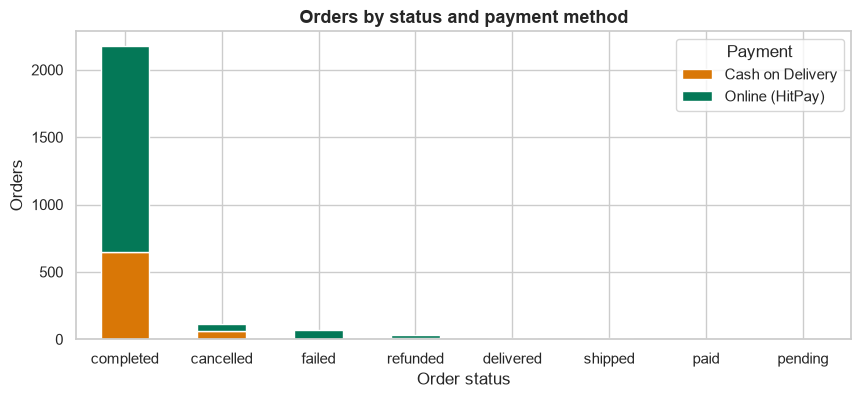

,products
status,
sold,2559
available,217
hidden,83


In [4]:
status = pd.crosstab(orders["status"], orders["payment_method"].map({"online": "Online (HitPay)", "cod": "Cash on Delivery"}), margins=True, margins_name="Total")
status = status.sort_values("Total", ascending=False)
display(status)

fig, ax = plt.subplots(figsize=(10, 4))
status.drop(index="Total").drop(columns="Total").plot.bar(stacked=True, ax=ax, color=["#d97706", "#047857"])
ax.set(title="Orders by status and payment method", xlabel="Order status", ylabel="Orders")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Payment")
save(fig, "01_order_status.png")
plt.show()

products["status"].value_counts().to_frame("products")

In [5]:
missing = pd.concat({
    "products": products.isna().sum(),
    "orders": orders.drop(columns=[c for c in orders if c.endswith("_my")]).isna().sum(),
}).rename("missing").to_frame()
missing = missing[missing["missing"] > 0]
missing["% of rows"] = [100 * m / (len(products) if t == "products" else len(orders)) for (t, _), m in zip(missing.index, missing["missing"])]
missing

missing  % of rows
orders paid_at                 183       7.58
       delivered_at            193       8.00
       delivery_failed_at     2395      99.21

**Finding:** 2,414 orders over two years (1 Nov 2024 – 7 Nov 2026). 2,221 (92%) count as revenue: RM 584,575 net, after RM 9,395 of refunds (1.6%), an average of RM 263 per order. 70% of orders are paid online. All 71 failed orders are online payments that didn't go through; 110 orders were cancelled. The only missing values are expected ones: `paid_at` / `delivered_at` are empty for unpaid, cancelled or undelivered orders, and `delivery_failed_at` is empty unless a COD delivery failed. Product fields have no gaps, so the data can be used as it is.

## 2. Revenue over time
Daily net revenue with a 7-day rolling average, then weekly (Monday–Sunday, as the dashboard) and monthly totals.
Annotated: 11.11 and 12.12 sales, and Hari Raya Aidilfitri 2025 (31 Mar) and 2026 (20 Mar).

saved 02_daily_revenue.png


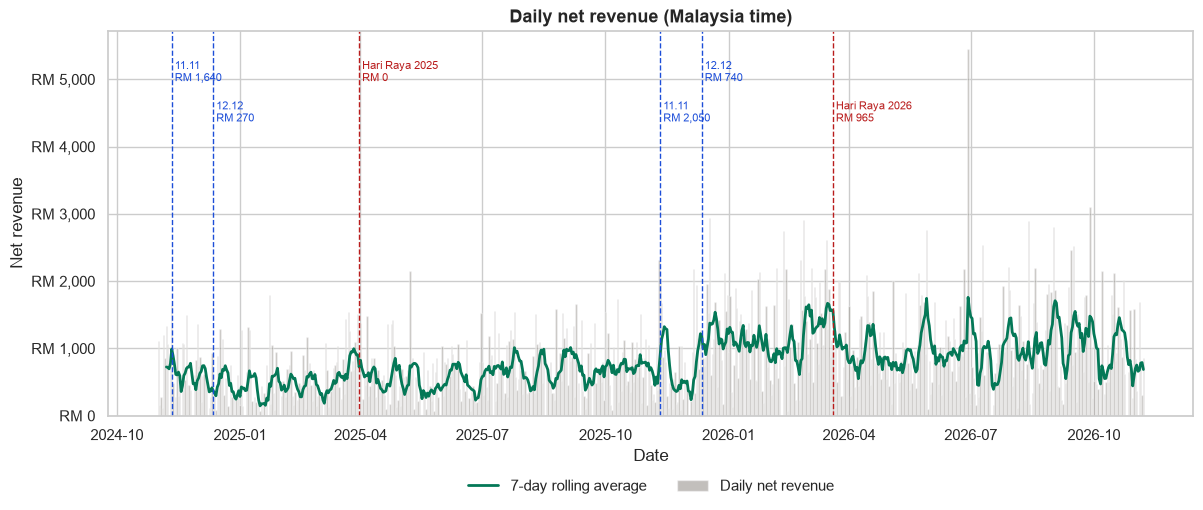

11.11           11 Nov 2024:  RM 1,640 vs 28-day average before  RM 698 (2.4x)
12.12           12 Dec 2024:    RM 270 vs 28-day average before  RM 557 (0.5x)
Hari Raya 2025  31 Mar 2025:      RM 0 vs 28-day average before  RM 661 (0.0x)
11.11           11 Nov 2025:  RM 2,050 vs 28-day average before  RM 745 (2.8x)
12.12           12 Dec 2025:    RM 740 vs 28-day average before  RM 613 (1.2x)
Hari Raya 2026  20 Mar 2026:    RM 965 vs 28-day average before RM 1,359 (0.7x)


In [6]:
all_days = pd.date_range(rev["day"].min(), rev["day"].max(), freq="D")
daily = rev.groupby("day")["net"].sum().reindex(all_days, fill_value=0.0)
daily_orders = rev.groupby("day").size().reindex(all_days, fill_value=0)
rolling = daily.rolling(7).mean()

EVENTS = {
    "2024-11-11": "11.11", "2024-12-12": "12.12", "2025-03-31": "Hari Raya 2025",
    "2025-11-11": "11.11", "2025-12-12": "12.12", "2026-03-20": "Hari Raya 2026",
}

fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(daily.index, daily.values, width=1.0, color="#78716c", alpha=0.45, label="Daily net revenue")
ax.plot(rolling.index, rolling.values, color="#047857", lw=2, label="7-day rolling average")
top = daily.max()
for i, (date, label) in enumerate(EVENTS.items()):
    d = pd.Timestamp(date)
    if all_days[0] <= d <= all_days[-1]:
        ax.axvline(d, color="#b91c1c" if "Raya" in label else "#1d4ed8", ls="--", lw=1)
        ax.text(d, top * (0.97 if i % 2 == 0 else 0.86), f" {label}\n {rm(daily[d])}", fontsize=8, va="top",
                color="#b91c1c" if "Raya" in label else "#1d4ed8")
ax.set(title="Daily net revenue (Malaysia time)", xlabel="Date", ylabel="Net revenue")
rm_axis(ax)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2, frameon=False)
save(fig, "02_daily_revenue.png")
plt.show()

for date, label in EVENTS.items():
    d = pd.Timestamp(date)
    before = daily[d - pd.Timedelta(days=28): d - pd.Timedelta(days=1)].mean()
    print(f"{label:15} {d:%d %b %Y}: {rm(daily[d]):>9} vs 28-day average before {rm(before):>7} ({daily[d] / before:.1f}x)")

saved

 02_weekly_revenue.png


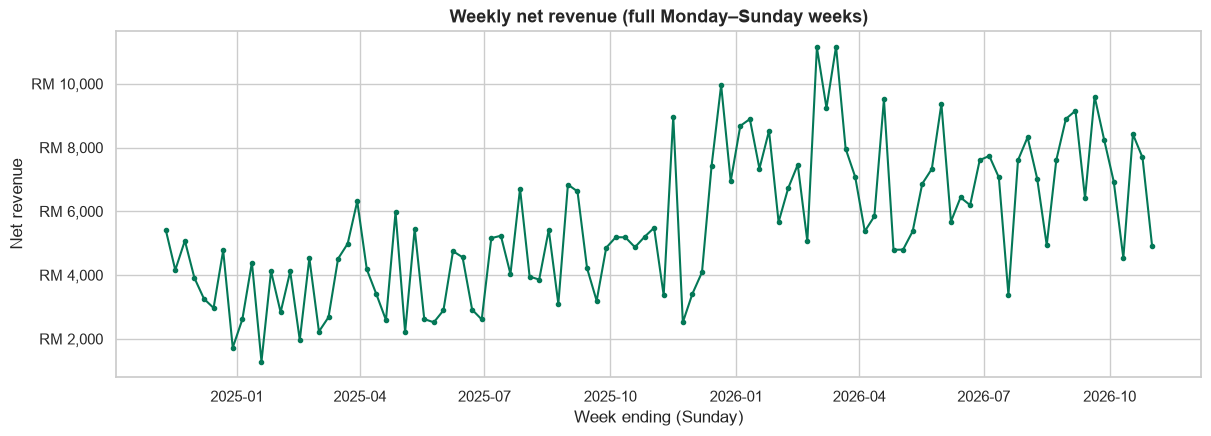

saved 02_monthly_revenue.png


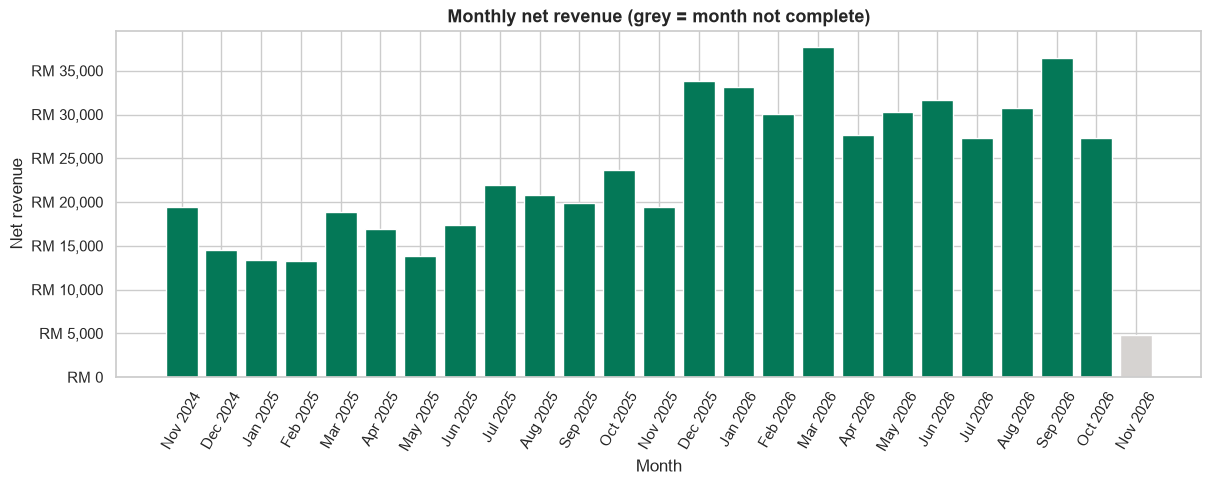

First 12 full months: RM 214,065 · last 12 full months: RM 365,700 (+71%)
Best month: Mar 2026 RM 37,695 · weakest: Feb 2025 RM 13,295
Days with zero revenue: 56 of 737


In [7]:
weekly = daily.resample("W-SUN").sum()
weekly_days = daily.resample("W-SUN").count()
weekly = weekly[weekly_days == 7]  # full Monday–Sunday weeks only

fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(weekly.index, weekly.values, marker="o", ms=3, color="#047857")
ax.set(title="Weekly net revenue (full Monday–Sunday weeks)", xlabel="Week ending (Sunday)", ylabel="Net revenue")
rm_axis(ax)
save(fig, "02_weekly_revenue.png")
plt.show()

monthly = daily.resample("MS").sum().to_frame("net")
monthly["days"] = daily.resample("MS").count()
monthly["orders"] = daily_orders.resample("MS").sum()
monthly["complete month"] = monthly["days"] == monthly.index.days_in_month

fig, ax = plt.subplots(figsize=(14, 4.5))
ax.bar(monthly.index.strftime("%b %Y"), monthly["net"], color=np.where(monthly["complete month"], "#047857", "#d6d3d1"))
ax.set(title="Monthly net revenue (grey = month not complete)", xlabel="Month", ylabel="Net revenue")
ax.tick_params(axis="x", rotation=60)
rm_axis(ax)
save(fig, "02_monthly_revenue.png")
plt.show()

full = monthly[monthly["complete month"]]
first12, last12 = full["net"].iloc[:12].sum(), full["net"].iloc[-12:].sum()
print(f"First 12 full months: {rm(first12)} · last 12 full months: {rm(last12)} ({last12 / first12 - 1:+.0%})")
print(f"Best month: {full['net'].idxmax():%b %Y} {rm(full['net'].max())} · weakest: {full['net'].idxmin():%b %Y} {rm(full['net'].min())}")
print(f"Days with zero revenue: {(daily == 0).sum()} of {len(daily)}")

**Finding:** Revenue grows clearly: the last 12 full months brought RM 365,700, +71% on the first 12 (RM 214,065). 11.11 is a reliable spike (2.4x the previous 28-day average in 2024, 2.8x in 2025), but 12.12 is not (0.5x and 1.2x). Hari Raya day itself is a dip (RM 0 in 2025, 0.7x in 2026), while the weeks before it are strong: March 2026 is the best month (RM 37,695). Daily revenue is noisy (56 of 737 days had no sales); the weekly and monthly series are much smoother.

## 3. Weekly pattern
Average net revenue and average number of paid orders per day of the week (all days, including zero days).

,net,orders,vs average
day,,,
Monday,787.95,2.94,-0.01
Tuesday,814.76,3.08,0.03
Wednesday,861.86,3.23,0.09
Thursday,849.76,3.27,0.07
Friday,863.21,3.29,0.09
Saturday,680.66,2.63,-0.14
Sunday,694.48,2.66,-0.12


saved 03_day_of_week.png


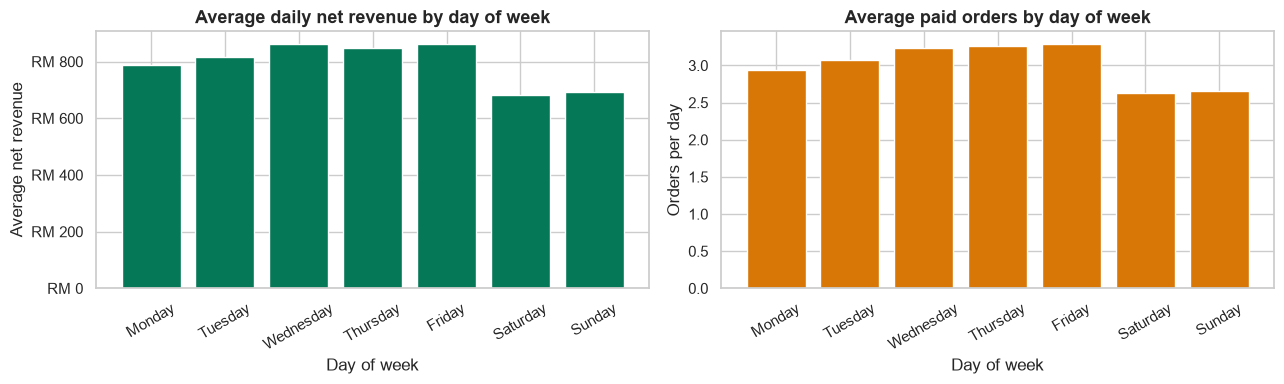

In [8]:
DAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
dow = pd.DataFrame({"net": daily, "orders": daily_orders})
dow["day"] = pd.Categorical(dow.index.day_name(), categories=DAYS, ordered=True)
by_dow = dow.groupby("day", observed=True)[["net", "orders"]].mean()
by_dow["vs average"] = by_dow["net"] / by_dow["net"].mean() - 1
display(by_dow)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(by_dow.index.astype(str), by_dow["net"], color="#047857")
axes[0].set(title="Average daily net revenue by day of week", xlabel="Day of week", ylabel="Average net revenue")
rm_axis(axes[0])
axes[1].bar(by_dow.index.astype(str), by_dow["orders"], color="#d97706")
axes[1].set(title="Average paid orders by day of week", xlabel="Day of week", ylabel="Orders per day")
for ax in axes:
    ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
save(fig, "03_day_of_week.png")
plt.show()

**Finding:** Wednesday to Friday are the busiest days (+7% to +9% above the average day), and Saturday and Sunday the quietest (−12% to −14%). Orders per day follow the same pattern (3.3 on Fridays vs 2.6 on Saturdays), so the difference is in the number of orders, not their size. The effect is real but small: about RM 180 a day between the best and worst day.

## 4. Time-series decomposition
Additive `seasonal_decompose` of daily net revenue with `period=7` (weekly cycle): trend, weekly seasonality and residual.

saved 04_decomposition.png


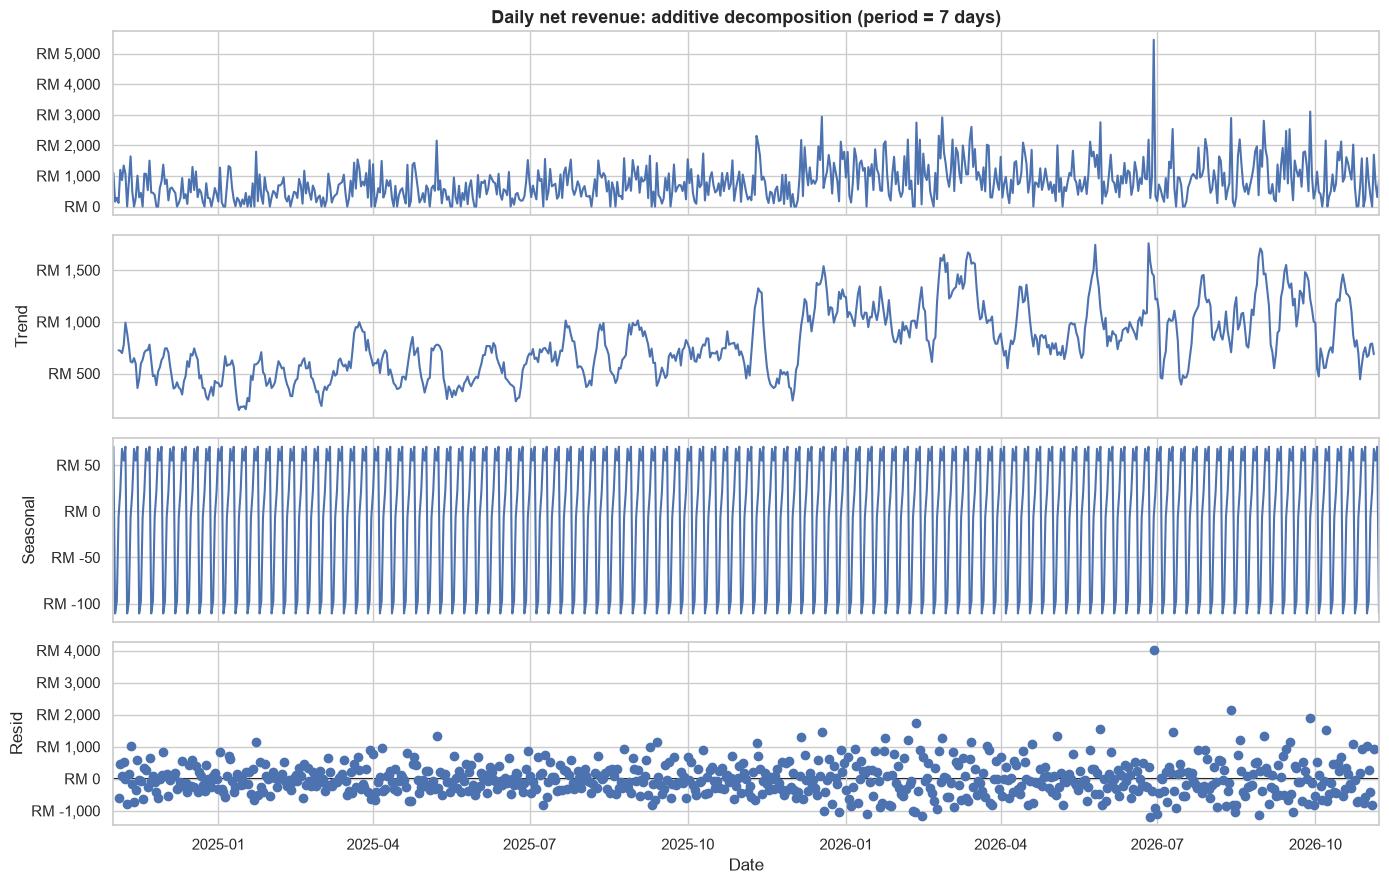

Weekly seasonal effect (RM vs trend): Mon -6, Tue +22, Wed +68, Thu +55, Fri +70, Sat -111, Sun -97
Trend: RM 651/day in the first month → RM 891/day in the last month
Share of variance: seasonal 1%, residual 70%


In [9]:
from statsmodels.tsa.seasonal import seasonal_decompose

decomp = seasonal_decompose(daily, model="additive", period=7)
fig = decomp.plot()
fig.set_size_inches(14, 9)
fig.axes[0].set_title("Daily net revenue: additive decomposition (period = 7 days)")
for ax in fig.axes:
    rm_axis(ax)
fig.axes[-1].set_xlabel("Date")
fig.tight_layout()
save(fig, "04_decomposition.png")
plt.show()

seasonal_by_day = pd.Series(decomp.seasonal.values, index=daily.index.day_name()).groupby(level=0).mean().reindex(DAYS)
resid = decomp.resid.dropna()
print("Weekly seasonal effect (RM vs trend):", ", ".join(f"{d[:3]} {v:+.0f}" for d, v in seasonal_by_day.items()))
print(f"Trend: {rm(decomp.trend.dropna().iloc[:30].mean())}/day in the first month → {rm(decomp.trend.dropna().iloc[-30:].mean())}/day in the last month")
print(f"Share of variance: seasonal {decomp.seasonal.var() / daily.var():.0%}, residual {resid.var() / daily.var():.0%}")

**Finding:** The trend rises from about RM 650 a day in the first month to RM 890 in the last. The weekly seasonal part is small (from −RM 111 on Saturday to +RM 70 on Friday) and explains only about 1% of the daily variance, while the residual explains about 70%. Most day-to-day movement is noise and one-off events (11.11, Raya), so a daily forecast will need wide intervals and holiday/event features.

## 5. Stationarity: ADF test and ACF/PACF
Augmented Dickey–Fuller test (H0: the series has a unit root, i.e. is not stationary) on the daily series,
its first difference and its weekly (lag-7) difference. ACF/PACF plots guide the SARIMA orders later.

,ADF statistic,p-value,lags used,5% critical value,stationary at 5%
series,,,,,
daily revenue,-3.61,0.01,14,-2.87,True
first difference,-8.84,0.00,20,-2.87,True
weekly difference (lag 7),-9.47,0.00,20,-2.87,True


saved 05_acf_pacf.png


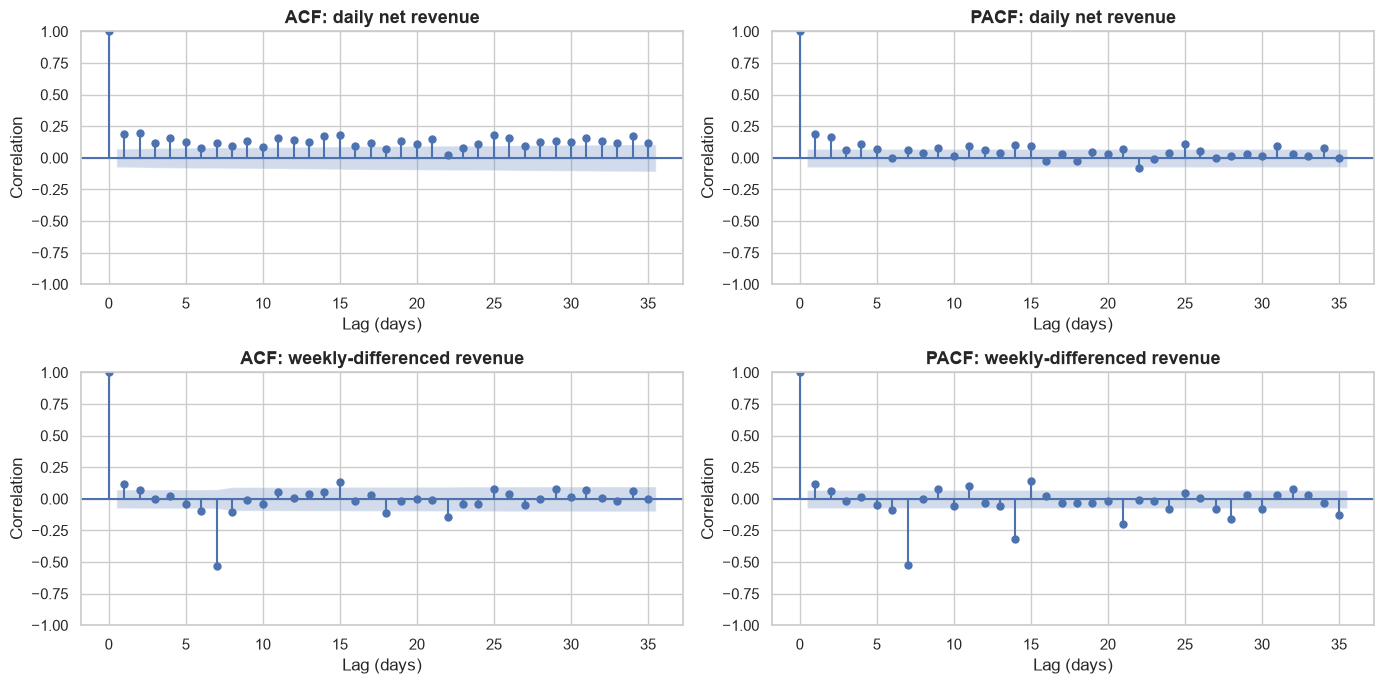

ACF lags 1, 7, 14: 0.19, 0.12, 0.17


In [10]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller

rows = []
for label, series in {"daily revenue": daily, "first difference": daily.diff().dropna(), "weekly difference (lag 7)": daily.diff(7).dropna()}.items():
    stat, p, lags, n, crit, _ = adfuller(series, autolag="AIC")
    rows.append({"series": label, "ADF statistic": stat, "p-value": p, "lags used": lags, "5% critical value": crit["5%"], "stationary at 5%": p < 0.05})
display(pd.DataFrame(rows).set_index("series"))

fig, axes = plt.subplots(2, 2, figsize=(14, 7))
plot_acf(daily, lags=35, ax=axes[0, 0], title="ACF: daily net revenue")
plot_pacf(daily, lags=35, ax=axes[0, 1], title="PACF: daily net revenue", method="ywm")
plot_acf(daily.diff(7).dropna(), lags=35, ax=axes[1, 0], title="ACF: weekly-differenced revenue")
plot_pacf(daily.diff(7).dropna(), lags=35, ax=axes[1, 1], title="PACF: weekly-differenced revenue", method="ywm")
for ax in axes.flat:
    ax.set(xlabel="Lag (days)", ylabel="Correlation")
fig.tight_layout()
save(fig, "05_acf_pacf.png")
plt.show()

from statsmodels.tsa.stattools import acf
a = acf(daily, nlags=14)
print("ACF lags 1, 7, 14:", ", ".join(f"{a[k]:.2f}" for k in (1, 7, 14)))

**Finding:** The ADF test rejects a unit root for daily revenue (p = 0.01), and strongly for the first and weekly differences (p < 0.001). The growth trend is weak compared with the daily noise. Autocorrelation is low (ACF 0.19 at lag 1, 0.12 at lag 7, 0.17 at lag 14), with small bumps at multiples of 7. For SARIMA this suggests low orders (p, q ≤ 1–2), d = 0 with a trend term or d = 1, and a weekly seasonal part (s = 7, P/Q ≤ 1), chosen by AIC. Prophet with Malaysian holidays (11.11, Raya, CNY) is a natural comparison.

## 6. Products: what sells
Units sold (items of revenue orders) by brand, category and UK size, the top 10 models, and the monthly trend of the top 5 models.

saved 06_units_by_brand.png


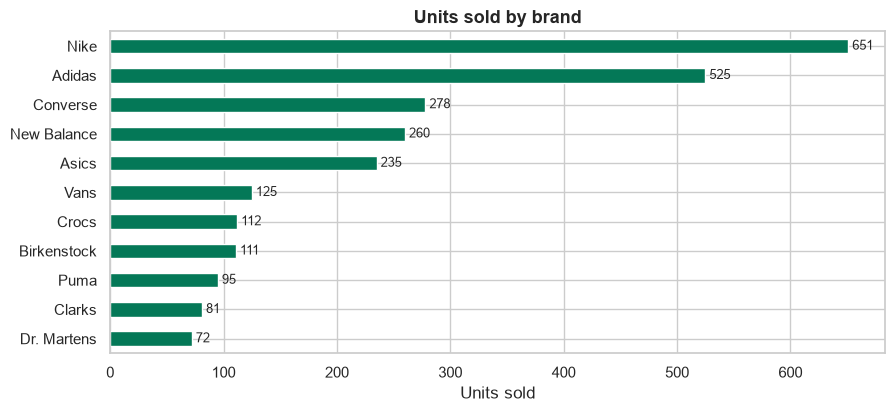

saved 06_units_by_category.png


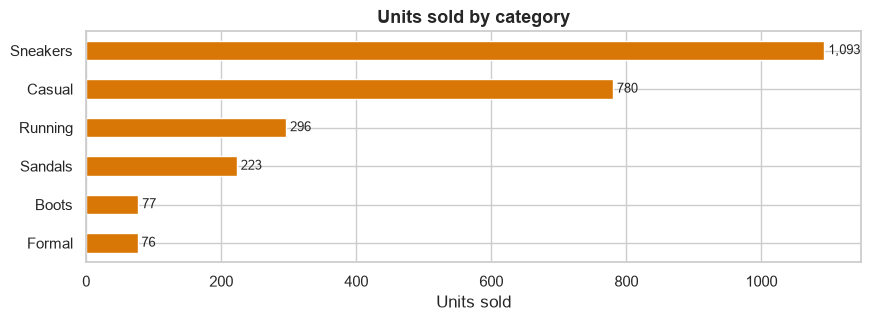

Brand share: Nike 26%, Adidas 21%, Converse 11%, New Balance 10%
Category share: Sneakers 43%, Casual 31%, Running 12%, Sandals 9%, Boots 3%, Formal 3%


In [11]:
def barh(series, title, xlabel, name, color="#047857"):
    fig, ax = plt.subplots(figsize=(10, max(3, 0.38 * len(series))))
    series.sort_values().plot.barh(ax=ax, color=color)
    ax.set(title=title, xlabel=xlabel, ylabel="")
    for i, v in enumerate(series.sort_values()):
        ax.text(v, i, f" {v:,.0f}", va="center", fontsize=9)
    save(fig, name)
    plt.show()


units = lambda col: sold.groupby(col)["quantity"].sum().astype(int).sort_values(ascending=False)
by_brand, by_category = units("brand"), units("category")
barh(by_brand, "Units sold by brand", "Units sold", "06_units_by_brand.png")
barh(by_category, "Units sold by category", "Units sold", "06_units_by_category.png", color="#d97706")
print("Brand share:", ", ".join(f"{b} {v / by_brand.sum():.0%}" for b, v in by_brand.head(4).items()))
print("Category share:", ", ".join(f"{c} {v / by_category.sum():.0%}" for c, v in by_category.items()))

saved 06_units_by_size.png


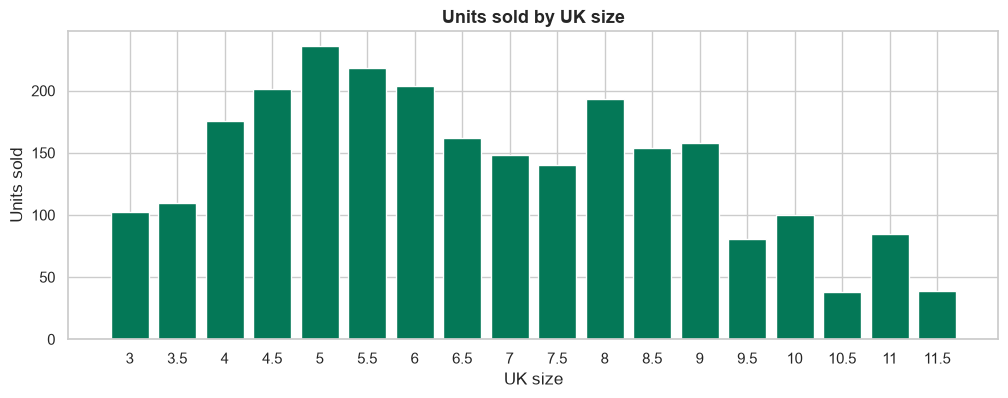

Most sold size: UK 5 (236 units); UK 6–10 = 53% of units


In [12]:
by_size = sold.groupby("size")["quantity"].sum().astype(int).sort_index()
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar([f"{s:g}" for s in by_size.index], by_size.values, color="#047857")
ax.set(title="Units sold by UK size", xlabel="UK size", ylabel="Units sold")
save(fig, "06_units_by_size.png")
plt.show()

core = by_size[(by_size.index >= 6) & (by_size.index <= 10)].sum() / by_size.sum()
print(f"Most sold size: UK {by_size.idxmax():g} ({by_size.max()} units); UK 6–10 = {core:.0%} of units")

saved 06_top10_models.png


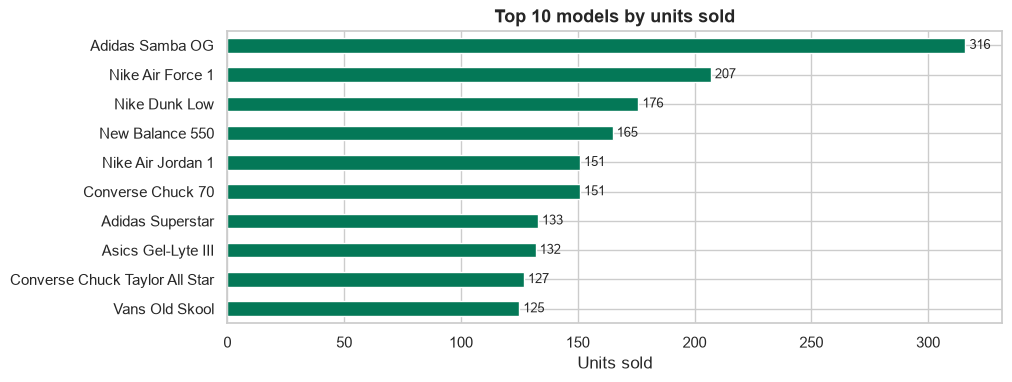

saved 06_top5_models_monthly.png


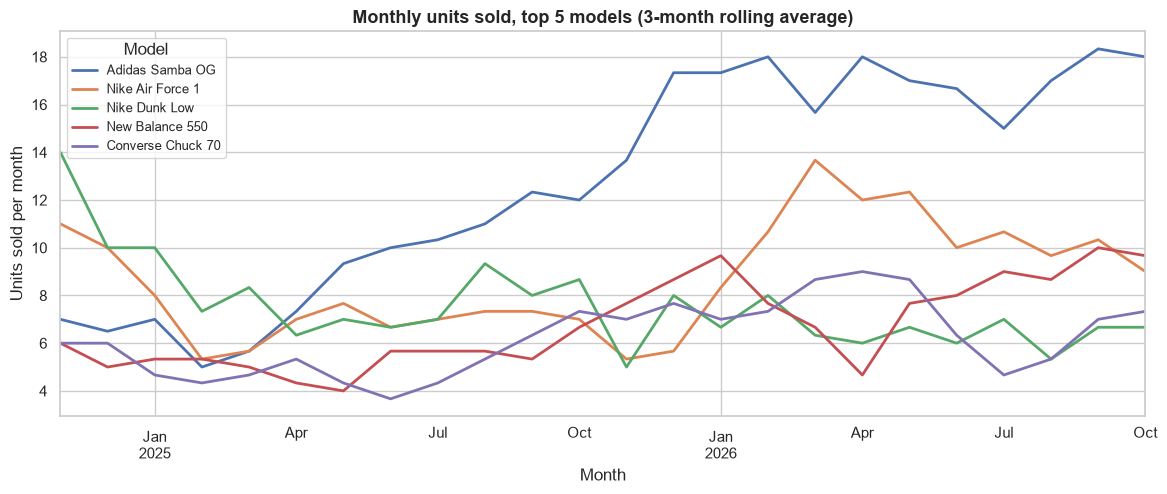

,first 6 months,last 6 months,slope (units/month),direction
name,,,,
Adidas Samba OG,43.00,99.00,0.58,rising
Nike Air Force 1,45.00,59.00,0.19,rising
Nike Dunk Low,49.00,41.00,-0.12,falling
New Balance 550,29.00,56.00,0.21,rising
Converse Chuck 70,30.00,36.00,0.12,rising


In [13]:
top10 = units("name").head(10)
barh(top10, "Top 10 models by units sold", "Units sold", "06_top10_models.png")

top5 = top10.head(5).index
months = pd.period_range(sold["month"].min(), sold["month"].max(), freq="M").to_timestamp()
monthly_models = (sold[sold["name"].isin(top5)].pivot_table(index="month", columns="name", values="quantity", aggfunc="sum")
                  .reindex(months, fill_value=0).fillna(0)[list(top5)])
monthly_models = monthly_models.iloc[:-1]  # drop the incomplete last month

fig, ax = plt.subplots(figsize=(14, 5))
monthly_models.rolling(3, min_periods=1).mean().plot(ax=ax, lw=2)
ax.set(title="Monthly units sold, top 5 models (3-month rolling average)", xlabel="Month", ylabel="Units sold per month")
ax.legend(title="Model", fontsize=9)
save(fig, "06_top5_models_monthly.png")
plt.show()

trend = pd.DataFrame({
    "first 6 months": monthly_models.iloc[:6].sum(),
    "last 6 months": monthly_models.iloc[-6:].sum(),
    "slope (units/month)": [np.polyfit(np.arange(len(monthly_models)), monthly_models[c], 1)[0] for c in monthly_models],
})
trend["direction"] = np.where(trend["slope (units/month)"] > 0.05, "rising", np.where(trend["slope (units/month)"] < -0.05, "falling", "flat"))
trend

**Finding:** Nike (26%) and Adidas (21%) lead, then Converse (11%) and New Balance (10%). Sneakers (43%) and Casual (31%) make up three quarters of units; Boots and Formal are only 3% each. Sizes have two peaks, UK 4.5–6 (women's range) and UK 8, with few sales above UK 10. Among the top models, the Adidas Samba OG is rising fast (43 units in the first 6 months, 99 in the last 6), the New Balance 550 and Nike Air Force 1 are rising, and the Nike Dunk Low is falling (49 → 41).

## 7. Stock vs demand
For each brand + category: pairs available now (status *available*, stock > 0) vs units sold in the last 30 days.
"Days of cover" = stock ÷ daily sales rate over those 30 days. Low cover with high demand is a restock signal.

saved 07_stock_vs_demand.png


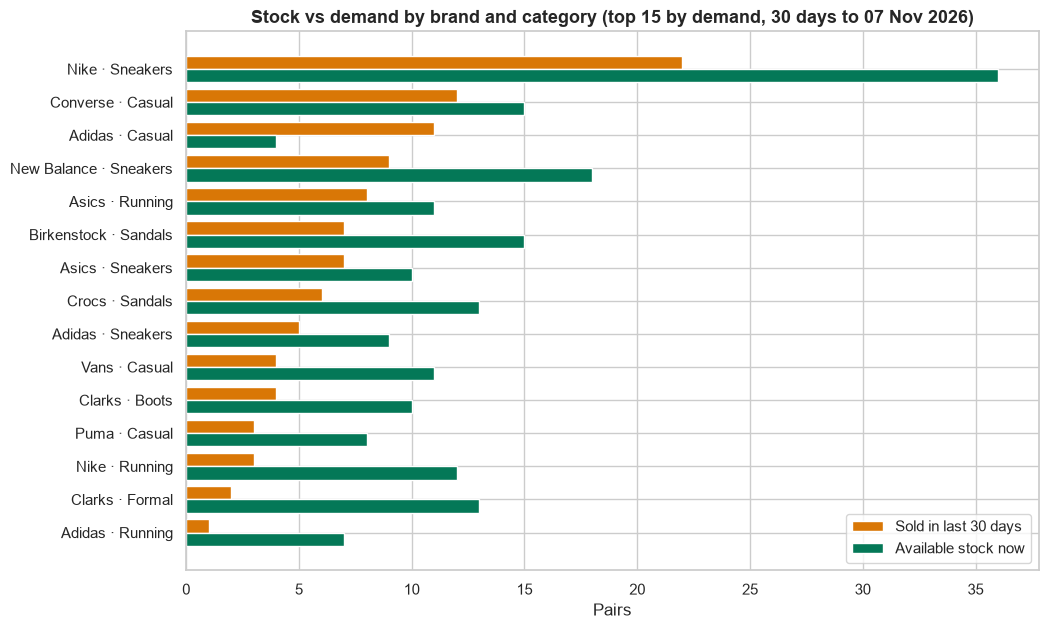

Last 30 days: 106 units sold · 217 pairs available now


,,available stock,sold last 30 days,days of cover
brand,category,,,
Nike,Sneakers,36,22,49.09
Converse,Casual,15,12,37.50
Adidas,Casual,4,11,10.91
New Balance,Sneakers,18,9,60.00
Asics,Running,11,8,41.25
Birkenstock,Sandals,15,7,64.29
Asics,Sneakers,10,7,42.86
Crocs,Sandals,13,6,65.00
Adidas,Sneakers,9,5,54.00


Under-stocked (sold ≥ 3, under 14 days of cover):


,,available stock,sold last 30 days,days of cover
brand,category,,,
Adidas,Casual,4,11,10.91


Possibly over-stocked (≥ 5 pairs, over 90 days of cover):


,,available stock,sold last 30 days,days of cover
brand,category,,,
Nike,Running,12,3,120.00
Clarks,Formal,13,2,195.00
Adidas,Running,7,1,210.00
Dr. Martens,Boots,8,1,240.00
Puma,Sneakers,10,1,300.00
Dr. Martens,Formal,7,0,inf


In [14]:
last_day = rev["day"].max()
recent = sold[sold["day"] > last_day - pd.Timedelta(days=30)]
stock = (products[(products["status"] == "available") & (products["stock"] > 0)]
         .groupby(["brand", "category"])["stock"].sum())
demand = recent.groupby(["brand", "category"])["quantity"].sum()
sd = pd.concat({"available stock": stock, "sold last 30 days": demand}, axis=1).fillna(0).astype(int)
sd["days of cover"] = np.where(sd["sold last 30 days"] > 0, sd["available stock"] / (sd["sold last 30 days"] / 30), np.inf)
sd = sd.sort_values("sold last 30 days", ascending=False)

plot = sd.head(15).iloc[::-1]
labels = [f"{b} · {c}" for b, c in plot.index]
fig, ax = plt.subplots(figsize=(11, 7))
y = np.arange(len(plot))
ax.barh(y + 0.2, plot["sold last 30 days"], height=0.4, color="#d97706", label="Sold in last 30 days")
ax.barh(y - 0.2, plot["available stock"], height=0.4, color="#047857", label="Available stock now")
ax.set_yticks(y, labels)
ax.set(title=f"Stock vs demand by brand and category (top 15 by demand, 30 days to {last_day:%d %b %Y})", xlabel="Pairs")
ax.legend()
save(fig, "07_stock_vs_demand.png")
plt.show()

print(f"Last 30 days: {int(recent['quantity'].sum())} units sold · {int(stock.sum())} pairs available now")
display(sd.head(15))
print("Under-stocked (sold ≥ 3, under 14 days of cover):")
display(sd[(sd["sold last 30 days"] >= 3) & (sd["days of cover"] < 14)])
print("Possibly over-stocked (≥ 5 pairs, over 90 days of cover):")
display(sd[(sd["available stock"] >= 5) & (sd["days of cover"] > 90)])

**Finding:** In the last 30 days 106 pairs sold, against 217 available now: about 61 days of cover overall, unevenly spread. **Adidas Casual** (the Samba) is under-stocked: 11 sold, 4 left, under 11 days of cover. Over-stocked groups are Dr. Martens (boots and formal), Clarks Formal, Puma Sneakers and Nike/Adidas Running, each with 120 days of cover or more. The restock model should work per brand + category (and size), using recent demand trends rather than all-time totals.

## 8. Pricing
Sold price (the item price at purchase) by condition, sold price vs the model's retail price, the price/retail ratio by brand,
and correlations between the numeric features a price model could use.

saved 08_price_by_condition.png


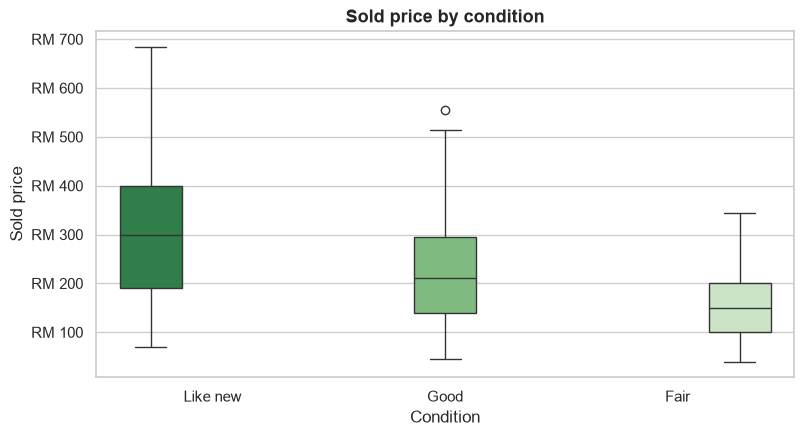

,median price (RM),median price/retail
condition label,,
Like new,300.00,0.56
Good,210.00,0.42
Fair,150.00,0.29


In [15]:
CONDITIONS = ["like_new", "good", "fair"]
COND_LABEL = {"like_new": "Like new", "good": "Good", "fair": "Fair"}
sold["ratio"] = sold["price"] / sold["retail_price"]
sold["condition label"] = pd.Categorical(sold["condition"].map(COND_LABEL), categories=[COND_LABEL[c] for c in CONDITIONS], ordered=True)

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=sold, x="condition label", y="price", hue="condition label", palette="Greens_r", legend=False, ax=ax)
ax.set(title="Sold price by condition", xlabel="Condition", ylabel="Sold price")
rm_axis(ax)
save(fig, "08_price_by_condition.png")
plt.show()
display(sold.groupby("condition label", observed=True)[["price", "ratio"]].median().rename(columns={"price": "median price (RM)", "ratio": "median price/retail"}))

saved 08_price_vs_retail.png


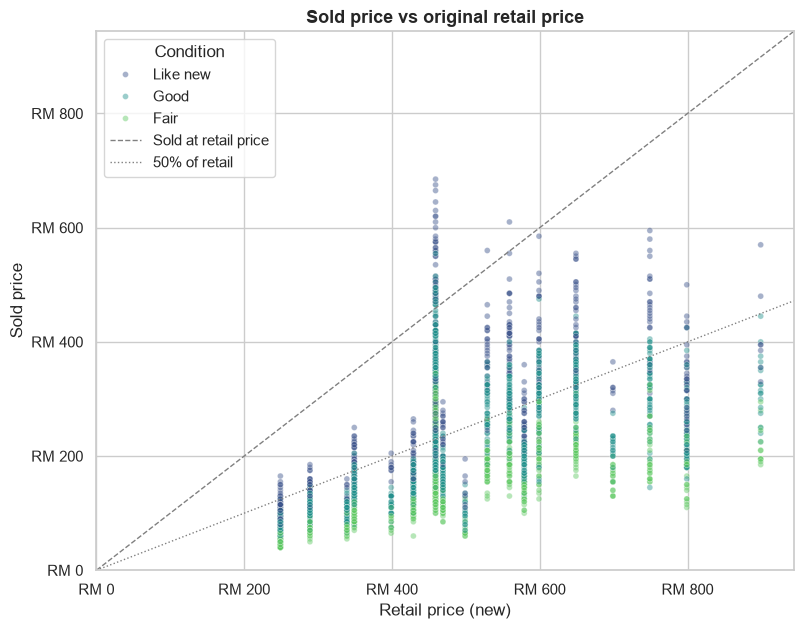

Correlation sold price ~ retail price: 0.52; median ratio 0.42


In [16]:
fig, ax = plt.subplots(figsize=(9, 7))
sns.scatterplot(data=sold, x="retail_price", y="price", hue="condition label", alpha=0.45, s=18, ax=ax, palette="viridis")
lim = sold[["retail_price", "price"]].max().max() * 1.05
ax.plot([0, lim], [0, lim], color="grey", ls="--", lw=1, label="Sold at retail price")
ax.plot([0, lim], [0, lim * 0.5], color="grey", ls=":", lw=1, label="50% of retail")
ax.set(title="Sold price vs original retail price", xlabel="Retail price (new)", ylabel="Sold price", xlim=(0, lim), ylim=(0, lim))
rm_axis(ax, "x")
rm_axis(ax, "y")
ax.legend(title="Condition")
save(fig, "08_price_vs_retail.png")
plt.show()
print(f"Correlation sold price ~ retail price: {sold['price'].corr(sold['retail_price']):.2f}; median ratio {sold['ratio'].median():.2f}")

saved 08_ratio_by_brand.png


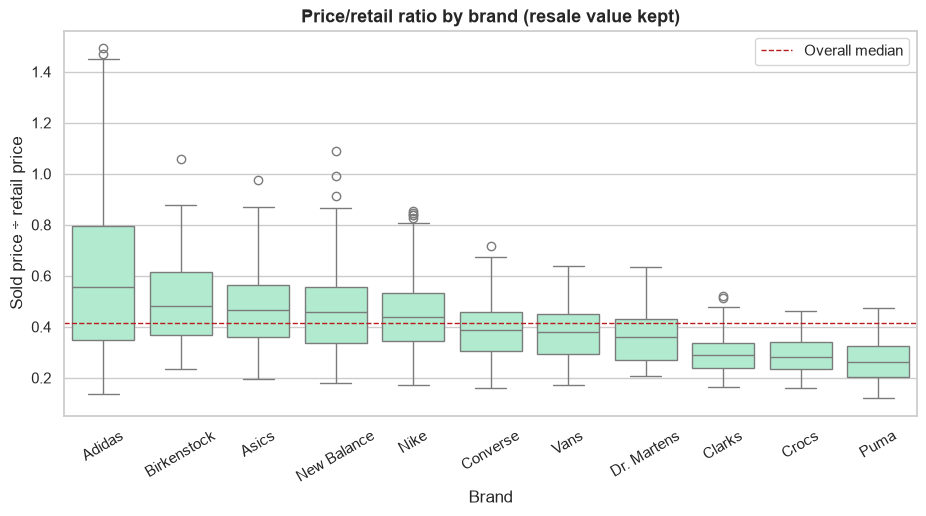

,median,count
brand,,
Adidas,0.56,525
Birkenstock,0.48,111
Asics,0.47,235
New Balance,0.46,260
Nike,0.44,651
Converse,0.39,278
Vans,0.38,125
Dr. Martens,0.36,72
Clarks,0.29,81


In [17]:
order_brands = sold.groupby("brand")["ratio"].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=sold, x="brand", y="ratio", order=order_brands, color="#a7f3d0", ax=ax)
ax.axhline(sold["ratio"].median(), color="#b91c1c", ls="--", lw=1, label="Overall median")
ax.set(title="Price/retail ratio by brand (resale value kept)", xlabel="Brand", ylabel="Sold price ÷ retail price")
ax.tick_params(axis="x", rotation=30)
ax.legend()
save(fig, "08_ratio_by_brand.png")
plt.show()
sold.groupby("brand")["ratio"].agg(["median", "count"]).sort_values("median", ascending=False)

saved 08_correlation_heatmap.png


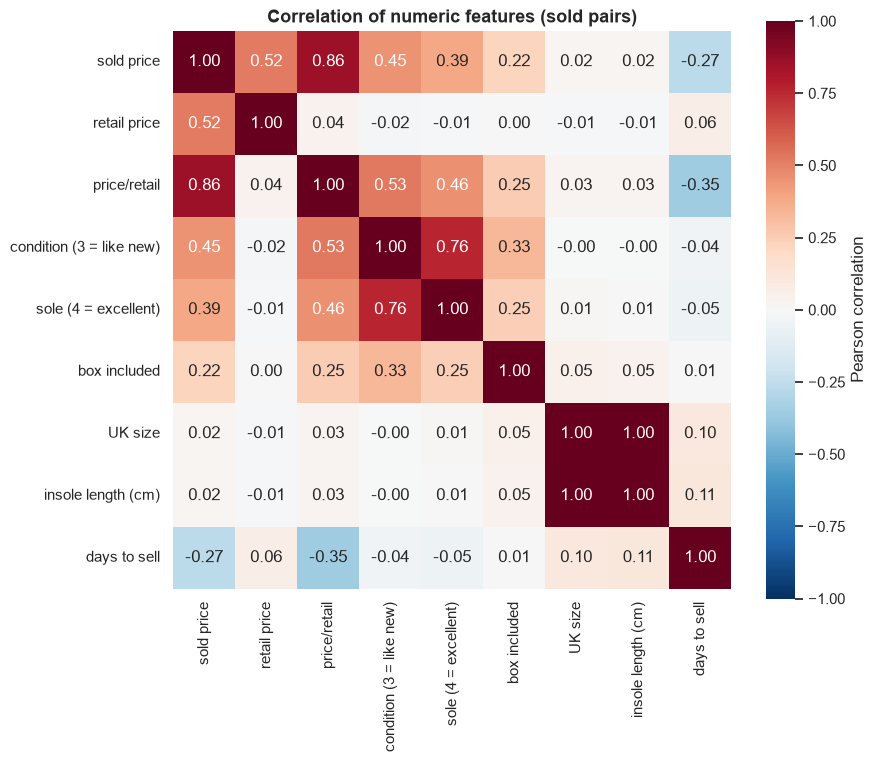

,sold price,price/retail,days to sell
sold price,1.00,0.86,-0.27
retail price,0.52,0.04,0.06
price/retail,0.86,1.00,-0.35
condition (3 = like new),0.45,0.53,-0.04
sole (4 = excellent),0.39,0.46,-0.05
box included,0.22,0.25,0.01
UK size,0.02,0.03,0.10
insole length (cm),0.02,0.03,0.11
days to sell,-0.27,-0.35,1.00


In [18]:
first_sale = sold.sort_values("ordered_at_my").drop_duplicates("product_id")
first_sale = first_sale.assign(days_to_sell=(first_sale["ordered_at_my"] - first_sale["listed_at_my"]).dt.total_seconds() / 86400)
features = pd.DataFrame({
    "sold price": first_sale["price"],
    "retail price": first_sale["retail_price"],
    "price/retail": first_sale["ratio"],
    "condition (3 = like new)": first_sale["condition"].map({"like_new": 3, "good": 2, "fair": 1}),
    "sole (4 = excellent)": first_sale["sole_condition"].map({"excellent": 4, "good": 3, "fair": 2, "worn": 1}),
    "box included": first_sale["box_included"],
    "UK size": first_sale["size"],
    "insole length (cm)": first_sale["insole_length_cm"],
    "days to sell": first_sale["days_to_sell"],
})
corr = features.corr()
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, cbar_kws={"label": "Pearson correlation"}, ax=ax)
ax.set_title("Correlation of numeric features (sold pairs)")
save(fig, "08_correlation_heatmap.png")
plt.show()
corr[["sold price", "price/retail", "days to sell"]].round(2)

**Finding:** Condition is the main price driver: like-new pairs sell for a median RM 300 (56% of retail), good for RM 210 (42%) and fair for RM 150 (29%). Retail price matters too (correlation 0.52 with the sold price), but brand changes how much value is kept: Adidas keeps 56% of retail, Puma 26%, Crocs 28% and Clarks 29%. Condition (0.53), sole condition (0.46) and box (0.25) correlate with the price/retail ratio; size has no effect. **Price/retail ratio** is a better target than the RM price, because it removes the model's retail price from the problem.

## 9. Days to sell
Days between a pair being listed (`products.created_at`) and the order that bought it (first revenue order), overall and by condition.
Also by price/retail ratio: do pairs priced high for their model sell slower?

saved 09_days_to_sell.png


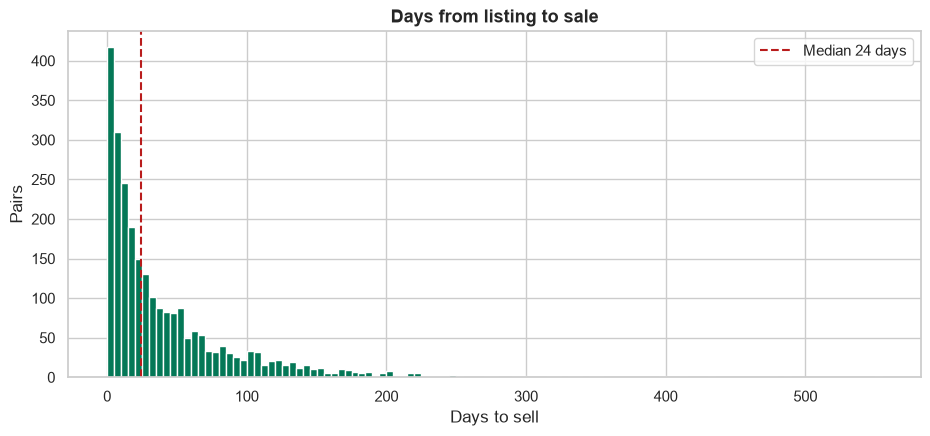

Median 24 days · mean 43 · sold within 7 days 22%, within 30 days 57%, after 90 days 14%


In [19]:
dts = first_sale["days_to_sell"].clip(lower=0)
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.hist(dts, bins=range(0, int(dts.max()) + 5, 5), color="#047857", edgecolor="white")
ax.axvline(dts.median(), color="#b91c1c", ls="--", label=f"Median {dts.median():.0f} days")
ax.set(title="Days from listing to sale", xlabel="Days to sell", ylabel="Pairs")
ax.legend()
save(fig, "09_days_to_sell.png")
plt.show()
print(f"Median {dts.median():.0f} days · mean {dts.mean():.0f} · sold within 7 days {(dts <= 7).mean():.0%}, within 30 days {(dts <= 30).mean():.0%}, after 90 days {(dts > 90).mean():.0%}")

saved 09_days_to_sell_by_condition.png


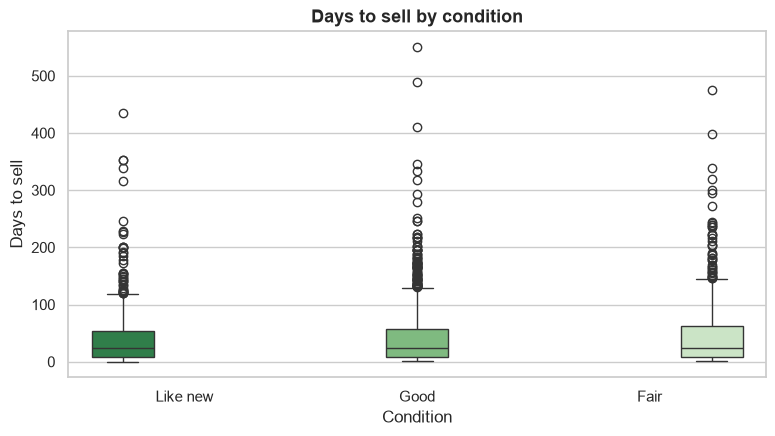

,count,25%,50%,75%
condition label,,,,
Like new,631.00,8.96,24.08,53.15
Good,"1,292.00",8.33,23.42,57.24
Fair,622.00,8.21,24.21,62.68


,median days to sell
price position,
cheapest 20%,45.11
2,36.94
3,22.84
4,18.33
priciest 20%,16.84


In [20]:
first_sale = first_sale.assign(days_to_sell=dts)
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=first_sale, x="condition label", y="days_to_sell", hue="condition label", palette="Greens_r", legend=False, ax=ax)
ax.set(title="Days to sell by condition", xlabel="Condition", ylabel="Days to sell")
save(fig, "09_days_to_sell_by_condition.png")
plt.show()
display(first_sale.groupby("condition label", observed=True)["days_to_sell"].describe()[["count", "25%", "50%", "75%"]])

# Price position within the same model: sold price vs the model's median sold price.
first_sale["vs model median"] = first_sale["price"] / first_sale.groupby("name")["price"].transform("median")
first_sale["price position"] = pd.qcut(first_sale["vs model median"], 5, labels=["cheapest 20%", "2", "3", "4", "priciest 20%"])
first_sale.groupby("price position", observed=True)["days_to_sell"].median().to_frame("median days to sell")

The cheapest pairs *within a model* sell slowest, which looks backwards. The check below shows why: the shop marks pairs down
15% after 45 days and again after 100 days, so slow pairs **end up** cheap. The sold price is partly a result of time on sale, not only its cause.

In [21]:
first_sale["time on sale"] = pd.cut(first_sale["days_to_sell"], [-1, 45, 100, 10_000],
                                    labels=["sold within 45 days", "45–100 days (1 markdown)", "over 100 days (2 markdowns)"])
first_sale.groupby("time on sale", observed=True)["vs model median"].agg(["median", "count"]).rename(
    columns={"median": "sold price ÷ model median", "count": "pairs"})

,sold price ÷ model median,pairs
time on sale,,
sold within 45 days,1.06,1714
45–100 days (1 markdown),0.91,511
over 100 days (2 markdowns),0.80,320


**Finding:** The median pair sells in 24 days: 22% within a week, 57% within 30 days and 14% after more than 90 days. Condition makes no difference to speed (median about 24 days for all three). Within a model, the cheapest pairs seem to sell slowest (45 vs 17 days), but that's the markdown rule working backwards: pairs sold within 45 days went for 1.06x the model's median price, 45–100 days for 0.91x, and over 100 days for 0.80x. The database only keeps the final price, not the original listing price.

## 10. Summary: key findings and what they mean for the models

- **Growing, noisy revenue.** Net revenue is RM 584,575 over two years, +71% year on year. Daily figures are noisy (residual about 70% of variance); weekly and monthly totals are much smoother.
- **Events matter more than weekdays.** 11.11 brings 2.4–2.8x a normal day, Hari Raya day is a dip (the weeks before it are strong), and 12.12 is unreliable. The weekday effect (Wed–Fri up, weekend down) is real but small (about ±10%).
- **Revenue forecast:** forecast weekly (or daily with intervals), using a SARIMA with low orders, s = 7 and d = 0 + trend or d = 1 (the series is already close to stationary, ADF p = 0.01). Compare it with Prophet with Malaysian holidays and 11.11 as regressors, and report wide prediction intervals.
- **Demand is concentrated and shifting.** Nike/Adidas and Sneakers/Casual dominate, sizes peak at UK 4.5–6 and UK 8, and model trends move (Samba rising fast, Dunk Low falling).
- **Restock:** predict demand per brand + category (and size) from the recent trend (last 30–90 days), not all-time totals. It should flag under-stocked groups like Adidas Casual (under 11 days of cover) and over-stocked ones like Dr. Martens and Clarks Formal (120+ days).
- **Price recommendation:** predict the price/retail ratio from condition, sole condition, box and brand (plus model), then multiply by retail price. Size can be left out.
- **Markdown bias.** Sold prices of slow pairs include markdowns (0.80x the model median after 100 days), so train on pairs sold within 45 days, or add time on sale as a feature. Storing the original listing price would fix this properly.
- **Days to sell** (median 24 days) does not depend on condition, so the price model, not condition, is what can speed up sales.